# RQ2 — ESRS Domain Adaptation: Compliance-Assessment Quality

**Research Question:** To what extent does disclosure-filtered ESRS context
injection improve evidence-grounded compliance assessment — comprising both
compliance-level classification and compliance-rationale quality — relative
to the same RAG pipeline without injected ESRS context?

**Experimental design:** Paired ablation study. Both conditions use the best
RQ1 pipeline. The single varied factor is whether
the generation prompt includes disclosure-filtered ESRS requirement text.

**Three evaluation layers:**

| Layer | What it measures | Role |
|---|---|---|
| 1. Deterministic compliance-level metrics | Low / Medium / High prediction accuracy | Objective classification sanity-check |
| 2. LLM-judge rationale evaluation (G-Eval, Liu et al. 2023) | Substantive alignment of generated vs gold rationale | Rationale quality signal |
| 3. Assessment Quality Score (AQS) | Combined level + rationale quality | Primary RQ2 endpoint |

**Key methodological decisions:**
- The LLM judge (Claude Sonnet 4.5) does **not** see the generated compliance
  level, only the generated rationale. This prevents anchoring bias where the
  judge conflates level-match with rationale quality (Zheng et al., 2024).
- The AQS uses a **multiplicative** composite: a sample with the
  wrong level receives zero credit regardless of rationale quality.
- The primary statistical test is the **Wilcoxon signed-rank test** on
  question-level deltas (n=12), which uses rank information and has higher
  power than the sign test for small samples (Wilcoxon, 1945).

## 1. Setup and Imports

In [1]:
import sys
import os
import json
import hashlib
import warnings
import logging
import math
from pathlib import Path
from collections import Counter, defaultdict
from dataclasses import dataclass
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, f1_score, confusion_matrix,
    cohen_kappa_score, precision_recall_fscore_support,
)

warnings.filterwarnings("ignore", category=UserWarning)
logging.basicConfig(level=logging.WARNING)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

# Parse .env (comment-tolerant, no python-dotenv dependency)
_env_path = PROJECT_ROOT / ".env"
if _env_path.exists():
    for _line in _env_path.read_text().splitlines():
        _line = _line.strip()
        if _line and not _line.startswith("#") and "=" in _line:
            _k, _, _v = _line.partition("=")
            _k = _k.strip()
            if _k:
                os.environ.setdefault(_k, _v.strip().strip('"').strip("'"))

from rag.config.settings import (
    GOLDEN_STANDARD_PATH, RQ2_RESULTS_DIR,
    BEST_PIPELINE_PATH, RQ2_RESULTS_VERSION,
)

CONDITIONS = ["full_system", "no_esrs_context"]
NB_CACHE_DIR = RQ2_RESULTS_DIR / "nb_cache"
LABELS = ["Low", "Medium", "High"]
LABEL_ORD = {"Low": 0, "Medium": 1, "High": 2}

# Publication-quality plot defaults
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "font.size": 11, "axes.titlesize": 13, "axes.labelsize": 12,
    "figure.dpi": 120, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
})
# Colorblind-friendly palette (Okabe-Ito inspired)
CLR_FULL = "#0072B2"    # blue
CLR_NO_ESRS = "#D55E00"  # vermillion
CLR_POS = "#009E73"      # green
CLR_NEG = "#D55E00"      # vermillion
CLR_ZERO = "#999999"     # grey

print(f"Project root : {PROJECT_ROOT}")
print(f"RQ2 results  : {RQ2_RESULTS_DIR}")
print(f"RQ2 version  : {RQ2_RESULTS_VERSION}")

Project root : /Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulation-Bot
RQ2 results  : /Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulation-Bot/data/artifacts/evaluation_results/rq2
RQ2 version  : 0e0efb2cbe


## 2. Load Best RQ1 Pipeline Configuration

Both conditions share the identical retrieval pipeline from RQ1;
only ESRS context injection differs.

In [2]:
best_config = {}
with open(BEST_PIPELINE_PATH) as f:
    for line in f:
        line = line.strip()
        if line and ":" in line:
            k, _, v = line.partition(":")
            best_config[k.strip()] = v.strip()

_best_pipeline_name = best_config.pop("_best_pipeline_name", "unknown")
_selection_reason = best_config.pop("_selection_reason", "")
print(f"Best pipeline: {_best_pipeline_name}")
print(f"Reason       : {_selection_reason}")
for k, v in best_config.items():
    print(f"  {k}: {v}")

Best pipeline: fixed_1024_hybrid_rerank
Reason       : Highest recall@15 (0.9616) in RQ1.
  chunk_strategy: fixed
  chunk_size: 1024
  retrieval_method: hybrid_rerank
  chunk_overlap_ratio: 0.125
  top_k: 15
  rrf_k: 60
  rerank_model: cross-encoder/ms-marco-MiniLM-L-6-v2


## 3. Load Golden Standard and Generation Cache

In [3]:
raw_golden = json.loads(GOLDEN_STANDARD_PATH.read_text(encoding="utf-8"))

golden_lookup = {}
samples = []
for q in raw_golden["questions"]:
    for pc in q["per_company"]:
        key = (q["id"], pc["company"])
        entry = {
            "question_id": q["id"], "question": q["question"],
            "esrs_standard": q["esrs_standard"],
            "esrs_disclosure_id": q.get("esrs_disclosure_id", ""),
            "company": pc["company"],
            "ground_truth_answer": pc.get("ground_truth_answer", ""),
            "fulfillment_level": pc["fulfillment_level"],
            "fulfillment_rationale": pc.get("fulfillment_rationale", ""),
            "evidence": pc.get("evidence", []),
        }
        golden_lookup[key] = entry
        samples.append(entry)

n_q = len(set(s["question_id"] for s in samples))
n_co = len(set(s["company"] for s in samples))
label_dist = Counter(s["fulfillment_level"] for s in samples)
print(f"Golden standard: {len(samples)} samples  ({n_q} questions × {n_co} companies)")
print(f"Label distribution: {dict(label_dist)}")

Golden standard: 204 samples  (12 questions × 17 companies)
Label distribution: {'High': 139, 'Low': 26, 'Medium': 39}


In [4]:
for condition in CONDITIONS:
    cdir = NB_CACHE_DIR / condition
    n_files = len(list(cdir.glob("*.json"))) if cdir.exists() else 0
    print(f"  {condition}: {n_files} cached files")
    if n_files == 0:
        raise RuntimeError(f"No cached generation files for {condition}. Run the pipeline first.")

  full_system: 204 cached files
  no_esrs_context: 204 cached files


## 4. Build Paired Sample Table

For each of the 204 golden-standard samples, match the cached generation
from each condition with the gold reference to create a fully paired dataset.

In [5]:
def _cache_key(question, company, condition, esrs_context_len):
    blob = f"{question}|{company}|{condition}|{esrs_context_len}"
    return hashlib.sha256(blob.encode()).hexdigest()[:16]


# ESRS context lengths per question (derived from actual generation cache).
# These are len(esrs_context_text) values used during the original generation run.
ESRS_CTX_LENGTHS = {
    "Q1": 14309, "Q2": 2517, "Q3": 10595, "Q4": 9590,
    "Q5": 4009, "Q6": 25453, "Q7": 9480, "Q8": 13080,
    "Q9": 19566, "Q10": 18847, "Q11": 8089, "Q12": 9763,
}

# Index all cache files by their hash stem
cache_index = {}
for condition in CONDITIONS:
    cdir = NB_CACHE_DIR / condition
    for fp in cdir.glob("*.json"):
        cache_index[(condition, fp.stem)] = fp


@dataclass
class Paired:
    question_id: str; question: str; esrs_standard: str
    esrs_disclosure_id: str; company: str
    gold_level: str; gold_rationale: str
    pred_level_full: str; pred_rationale_full: str
    pred_level_no_esrs: str; pred_rationale_no_esrs: str


def _norm_level(v):
    return {"low": "Low", "medium": "Medium", "high": "High"}.get(str(v).strip().lower(), v)


def _extract_gen(cache_entry):
    """Extract compliance_level and compliance_rationale from a cache entry.

    The cache stores fields at the top level (compliance_level, rationale)
    and also in a raw_response JSON string (with compliance_rationale).
    We prefer raw_response for the rationale key name consistency.
    """
    level = cache_entry.get("compliance_level", "")
    # Try raw_response first for canonical field names
    raw = cache_entry.get("raw_response")
    if raw and isinstance(raw, str):
        try:
            parsed = json.loads(raw)
            return parsed.get("compliance_level", level), parsed.get("compliance_rationale", "")
        except (json.JSONDecodeError, TypeError):
            pass
    # Fallback to top-level keys
    return level, cache_entry.get("rationale", "")


paired = []
missing = []
for s in samples:
    qid, co = s["question_id"], s["company"]
    ctx_len = ESRS_CTX_LENGTHS.get(qid, 0)
    cache_data = {}
    for cond in CONDITIONS:
        hk = _cache_key(s["question"], co, cond, ctx_len if cond == "full_system" else 0)
        fp = cache_index.get((cond, hk))
        if fp is None:
            missing.append((qid, co, cond))
            continue
        cache_data[cond] = json.loads(fp.read_text("utf-8"))
    if len(cache_data) < 2:
        continue
    full_level, full_rat = _extract_gen(cache_data["full_system"])
    no_level, no_rat = _extract_gen(cache_data["no_esrs_context"])
    paired.append(Paired(
        question_id=qid, question=s["question"],
        esrs_standard=s["esrs_standard"],
        esrs_disclosure_id=s["esrs_disclosure_id"], company=co,
        gold_level=s["fulfillment_level"],
        gold_rationale=s.get("fulfillment_rationale", ""),
        pred_level_full=_norm_level(full_level),
        pred_rationale_full=full_rat,
        pred_level_no_esrs=_norm_level(no_level),
        pred_rationale_no_esrs=no_rat,
    ))

print(f"Paired samples: {len(paired)} / {len(samples)}")
if missing:
    print(f"Missing: {len(missing)} (first 3: {missing[:3]})")

Paired samples: 204 / 204


## 5. Deterministic Compliance-Level Metrics

Evaluate the first assessment component: how well does each condition predict
the gold Low / Medium / High compliance level?

**Metrics** (standard for ordinal classification):
- **Exact accuracy**: fraction of exact label matches
- **Macro-F1**: arithmetic mean of per-class F1, giving equal weight to minority classes
- **Weighted Cohen's κ**: ordinal agreement using linear weights (Cohen, 1968)

In [6]:
def _level_metrics(ps, cond):
    """Compute deterministic compliance-level metrics for one condition."""
    gold = [s.gold_level for s in ps if s.gold_level in LABELS]
    pred = [getattr(s, f"pred_level_{cond}") for s in ps if s.gold_level in LABELS]
    valid = [(g, p) for g, p in zip(gold, pred) if p in LABELS]
    if not valid:
        return {}
    g, p = zip(*valid)
    g, p = list(g), list(p)
    n = len(g)

    cm = confusion_matrix(g, p, labels=LABELS)
    macro_f1 = f1_score(g, p, labels=LABELS, average="macro", zero_division=0)
    exact_acc = accuracy_score(g, p)
    kappa = cohen_kappa_score(g, p, labels=LABELS, weights="linear")

    per_label = {}
    prec, rec, f1s, sup = precision_recall_fscore_support(
        g, p, labels=LABELS, zero_division=0)
    for i, lbl in enumerate(LABELS):
        per_label[lbl] = {"precision": prec[i], "recall": rec[i],
                          "f1": f1s[i], "support": int(sup[i])}

    return {
        "n": n, "exact_accuracy": exact_acc, "macro_f1": macro_f1,
        "weighted_kappa": kappa,
        "confusion_matrix": cm, "per_label": per_label,
    }


lm = {}
for cond_key, cond_label in [("full", "full_system"), ("no_esrs", "no_esrs_context")]:
    lm[cond_label] = _level_metrics(paired, cond_key)

# Print comparison table
print(f"{'Metric':<25s} {'Full System':>12s} {'No ESRS':>12s} {'Δ (Full−No)':>12s}")
print("─" * 65)
for metric in ["exact_accuracy", "macro_f1", "weighted_kappa"]:
    vf = lm["full_system"].get(metric, float("nan"))
    vn = lm["no_esrs_context"].get(metric, float("nan"))
    d = vf - vn
    print(f"{metric:<25s} {vf:>12.4f} {vn:>12.4f} {d:>+12.4f}")

Metric                     Full System      No ESRS  Δ (Full−No)
─────────────────────────────────────────────────────────────────
exact_accuracy                  0.6765       0.6814      -0.0049
macro_f1                        0.5182       0.5455      -0.0273
weighted_kappa                  0.3830       0.3996      -0.0166


## 6. Majority-Class Baseline

In [7]:
all_gold = [s.gold_level for s in paired if s.gold_level in LABELS]
maj = max(LABELS, key=all_gold.count)
maj_pred = [maj] * len(all_gold)
maj_acc = accuracy_score(all_gold, maj_pred)
maj_f1 = f1_score(all_gold, maj_pred, labels=LABELS, average="macro", zero_division=0)
print(f"Majority label: {maj}  (n={all_gold.count(maj)}/{len(all_gold)}, {all_gold.count(maj)/len(all_gold):.1%})")
print(f"Majority baseline — Exact Acc: {maj_acc:.4f}, Macro-F1: {maj_f1:.4f}")
for cond in ["full_system", "no_esrs_context"]:
    f1_c = lm[cond]["macro_f1"]
    print(f"  {cond}: Macro-F1 {f1_c:.4f}  (Δ vs majority: {f1_c - maj_f1:+.4f})")

Majority label: High  (n=139/204, 68.1%)
Majority baseline — Exact Acc: 0.6814, Macro-F1: 0.2702
  full_system: Macro-F1 0.5182  (Δ vs majority: +0.2481)
  no_esrs_context: Macro-F1 0.5455  (Δ vs majority: +0.2754)


## 7. LLM-Judge Rationale Evaluation

**Method:** G-Eval-inspired reference-based evaluation (Liu et al., 2023, EMNLP).
Claude Sonnet 4.5 acts as a judge, comparing each generated rationale against
the gold fulfillment rationale on a **1–5 Likert scale** with explicit
chain-of-thought evaluation steps.

**Critical design decision:** The judge does **not** see the generated
compliance level — only the generated rationale and the gold context. This
prevents anchoring bias where the judge conflates level-match with rationale
quality (Zheng et al., 2024). The judge evaluates rationale substance
independently of whether the level prediction happened to match.

**Score-to-verdict mapping** (deterministic, applied post-hoc):
- 4–5 → `aligned`, 3 → `partially_aligned`, 1–2 → `misaligned`
- Normalized to [0, 1]: `(score − 1) / 4`

**Deviations from G-Eval and justification:**

G-Eval's core scoring innovation uses per-token log-probabilities to compute
a probability-weighted expected score — e.g. `1·P("1") + 2·P("2") + … + 5·P("5")`
— yielding a continuous value such as 3.74 rather than a discrete integer.
This approach has two prerequisites that are not met here:

1. **API access to log-probabilities.** The Anthropic Messages API does not
   expose per-token log-probabilities. The information is simply not in the
   response object, making G-Eval's exact procedure technically unrealisable
   with Claude as the judge.
2. **Score as the first generated token.** G-Eval's logprob trick requires
   the score to be elicited as the very next token. Our prompt first generates
   chain-of-thought reasoning inside a JSON object; the score token appears
   deep in the sequence. The faithful G-Eval procedure would require two
   separate API calls — one to generate the reasoning, one to elicit the score
   token in isolation — doubling API cost and restructuring the judge module.

We therefore use **single-call greedy decoding**, which is the standard
practical fallback in applied G-Eval adaptations. The discretisation loss
(scores confined to {0, 0.25, 0.50, 0.75, 1.0} after normalisation) is
negligible at the aggregate level: our primary outcome is a mean AQS across
204 samples compared via a Wilcoxon test on 12 question-level deltas, where
the difference between discrete and continuous scoring washes out.

In [8]:
from rag.evaluation.rq2_judge import (
    run_judge_batch, get_judge_version, JUDGE_CACHE_DIR,
)

jv = get_judge_version()
n_cached = len(list(JUDGE_CACHE_DIR.glob("*.json"))) if JUDGE_CACHE_DIR.exists() else 0
print(f"Judge version: {jv}")
print(f"Cached judge results: {n_cached}")

Judge version: v2_79b8809bad
Cached judge results: 927


In [9]:
judge_batches = {}
for cond in CONDITIONS:
    batch = []
    for s in paired:
        pred_level = s.pred_level_full if cond == "full_system" else s.pred_level_no_esrs
        pred_rat = s.pred_rationale_full if cond == "full_system" else s.pred_rationale_no_esrs
        batch.append({
            "question": s.question, "esrs_standard": s.esrs_standard,
            "esrs_disclosure_id": s.esrs_disclosure_id,
            "gold_fulfillment_level": s.gold_level,
            "gold_fulfillment_rationale": s.gold_rationale,
            "generated_compliance_level": pred_level,
            "generated_compliance_rationale": pred_rat,
            "company": s.company,
        })
    judge_batches[cond] = batch
    print(f"  {cond}: {len(batch)} samples")
print(f"Total judge evaluations: {sum(len(b) for b in judge_batches.values())}")

  full_system: 204 samples
  no_esrs_context: 204 samples
Total judge evaluations: 408


In [10]:
judge_results = {}
for cond in CONDITIONS:
    res = run_judge_batch(judge_batches[cond], cond, dry_run=False)
    judge_results[cond] = res
    n_api = sum(1 for r in res if not r.get("was_cached", False))
    print(f"  {cond}: {len(res)} total, {len(res) - n_api} cached, {n_api} API calls")
    verdicts = Counter(r["rationale_verdict"] for r in res)
    print(f"    Verdicts: {dict(verdicts)}")

  full_system: 204 total, 204 cached, 0 API calls
    Verdicts: {'aligned': 134, 'partially_aligned': 13, 'misaligned': 57}
  no_esrs_context: 204 total, 204 cached, 0 API calls
    Verdicts: {'aligned': 134, 'misaligned': 54, 'partially_aligned': 16}


## 8. Aggregate Judge Metrics

In [11]:
def agg_judge(res):
    """Aggregate judge results for one condition."""
    scores = [r["rationale_score"] for r in res]                # 1-5 Likert
    scores_norm = [r["rationale_score_normalized"] for r in res]  # 0-1
    verdicts = [r["rationale_verdict"] for r in res]
    n = len(res)
    return {
        "mean_score": np.mean(scores),
        "std_score": np.std(scores),
        "mean_score_normalized": np.mean(scores_norm),
        "aligned": sum(1 for v in verdicts if v == "aligned") / n,
        "partial": sum(1 for v in verdicts if v == "partially_aligned") / n,
        "misaligned": sum(1 for v in verdicts if v == "misaligned") / n,
        "aligned_or_partial": sum(1 for v in verdicts if v in ("aligned", "partially_aligned")) / n,
        "error_tags": Counter(
            tag for r in res for tag in r.get("error_tags", []) if tag != "none"
        ),
    }


jm = {cond: agg_judge(judge_results[cond]) for cond in CONDITIONS}

print(f"{'Metric':<30s} {'Full System':>12s} {'No ESRS':>12s} {'Δ':>10s}")
print("─" * 66)
for metric in ["mean_score", "mean_score_normalized", "aligned", "partial", "misaligned"]:
    vf = jm["full_system"][metric]
    vn = jm["no_esrs_context"][metric]
    print(f"{metric:<30s} {vf:>12.4f} {vn:>12.4f} {vf - vn:>+10.4f}")
print()
print("Error tag distribution:")
for cond in CONDITIONS:
    print(f"  {cond}: {dict(jm[cond]['error_tags'])}")

Metric                          Full System      No ESRS          Δ
──────────────────────────────────────────────────────────────────
mean_score                           3.8382       3.7843    +0.0539
mean_score_normalized                0.7096       0.6961    +0.0135
aligned                              0.6569       0.6569    +0.0000
partial                              0.0637       0.0784    -0.0147
misaligned                           0.2794       0.2647    +0.0147

Error tag distribution:
  full_system: {'omission': 23, 'different_level_support': 57, 'contradiction': 45}
  no_esrs_context: {'omission': 33, 'different_level_support': 54, 'contradiction': 36}


## 9. Assessment Quality Score — PRIMARY RQ2 ENDPOINT

The Assessment Quality Score (AQS) combines classification correctness with
rationale quality using a **multiplicative** formulation:

**AQS** = `I(level_correct) × rationale_score_normalized`, averaged across samples.

A sample with an incorrect compliance level receives zero credit regardless
of rationale quality, because a compliance assessment with an incorrect
conclusion is not useful in regulatory contexts. This is analogous to the
accuracy × confidence decomposition in calibration literature (Guo et al.,
2017) and to the multiplicative quality metric in Pyramid evaluation
(Nenkova & Passonneau, 2004).

In [12]:
def joint_metrics(ps, jr, cond):
    """Compute the Assessment Quality Score (AQS)."""
    aqs_scores = []

    for s, r in zip(ps, jr):
        pred = s.pred_level_full if cond == "full_system" else s.pred_level_no_esrs
        level_correct = (pred == s.gold_level)
        score_norm = r["rationale_score_normalized"]

        # AQS: multiplicative composite
        aqs = float(level_correct) * score_norm
        aqs_scores.append(aqs)

    n = len(ps)
    return {
        "aqs": np.mean(aqs_scores),
        "aqs_std": np.std(aqs_scores),
        "n": n,
    }


jt = {}
for cond in CONDITIONS:
    jt[cond] = joint_metrics(paired, judge_results[cond], cond)

print(f"{'='*72}")
print(f"PRIMARY RQ2 ENDPOINT — Assessment Quality Score (AQS)")
print(f"  Full system    : {jt['full_system']['aqs']:.4f}")
print(f"  No ESRS context: {jt['no_esrs_context']['aqs']:.4f}")
print(f"  Δ (Full − No)  : {jt['full_system']['aqs'] - jt['no_esrs_context']['aqs']:+.4f}")
print(f"{'='*72}")

PRIMARY RQ2 ENDPOINT — Assessment Quality Score (AQS)
  Full system    : 0.6336
  No ESRS context: 0.6152
  Δ (Full − No)  : +0.0184


## 10. Manual Audit Calibration Subset

To validate that the LLM judge's 1–5 Likert scores reflect human judgement, we
draw a stratified 20-sample subset for manual review. The selection strategy
guarantees coverage across all 11 ESRS standards in the golden standard (one sample per standard,
filling the remaining 9 slots with a level-balanced rotation across Low /
Medium / High gold fulfillment).

The exported CSV places the judge's scores for **both** conditions
(`full_system` and `no_esrs_context`) side-by-side with empty `human_*`
columns, so the reviewer can rate the same rationale that each condition
produced and an inter-rater agreement (Cohen's κ, Pearson r) can be computed
between judge and human.

> **Note for the reader:** The exact same 20 samples are reused in RQ3
> (notebook 05) to calibrate the multi-dimensional RQ3 judge. Selecting the
> subset here — at the first point a judge appears in the thesis — keeps the
> human-evaluation cohort consistent across both research questions and lets
> a single audit pass cover both notebooks.

In [13]:
import random

# --- Stratified sampling for manual audit ---
# Identical algorithm and seed to RQ3 (notebook 05). Because `paired` and the
# `rq3_samples` list in notebook 05 are both built by iterating over the
# golden-standard samples in the same order and contain all 204 samples, the
# resulting indices map to the same (question_id, company) pairs in both
# notebooks. This guarantees a single audit pass is valid for RQ2 and RQ3.
random.seed(42)
AUDIT_SIZE = 20

# Group samples by ESRS standard
by_standard = defaultdict(list)
for i, s in enumerate(paired):
    by_standard[s.esrs_standard].append(i)

# Round 1: one sample per standard (11 standards -> 11 samples)
audit_indices = set()
standards_sorted = sorted(by_standard.keys())
for std in standards_sorted:
    candidates = by_standard[std][:]
    random.shuffle(candidates)
    audit_indices.add(candidates[0])

# Round 2: fill the remaining 8 slots, balanced across gold fulfillment levels
remaining = [i for i in range(len(paired)) if i not in audit_indices]
random.shuffle(remaining)
by_level = defaultdict(list)
for i in remaining:
    by_level[paired[i].gold_level].append(i)

level_cycle = ["Low", "Medium", "High"]
level_idx = 0
while len(audit_indices) < AUDIT_SIZE:
    level = level_cycle[level_idx % 3]
    if by_level[level]:
        audit_indices.add(by_level[level].pop(0))
    level_idx += 1
    if not any(by_level[l] for l in level_cycle):
        break  # safety: stop if all levels exhausted

audit_indices = sorted(audit_indices)
audit_samples = [paired[i] for i in audit_indices]

print(f"Audit subset size       : {len(audit_samples)}")
print(f"Standards covered       : {len(set(s.esrs_standard for s in audit_samples))} / {len(standards_sorted)}")
print(f"Level distribution      : {dict(Counter(s.gold_level for s in audit_samples))}")
print(f"Example (first 3 pairs) : {[(s.question_id, s.company) for s in audit_samples[:3]]}")


Audit subset size       : 20
Standards covered       : 11 / 11
Level distribution      : {'High': 12, 'Medium': 4, 'Low': 4}
Example (first 3 pairs) : [('Q1', 'Eni'), ('Q1', 'Helleniq'), ('Q1', 'TotalEnergies')]


In [14]:
# --- Export the audit CSV template (judge vs human, both conditions) ---
# For each audit sample we record the judge's 1-5 score and verdict for both
# the full_system and no_esrs_context conditions, plus empty `human_*` columns
# the reviewer fills in. The same 20 (question_id, company) pairs are reused
# by notebook 05 (RQ3), so a single human pass calibrates both judges.

# Build a quick (question_id, company) -> judge result lookup per condition
def _judge_lookup(condition):
    out = {}
    for s, r in zip(paired, judge_results[condition]):
        out[(s.question_id, s.company)] = r
    return out


_jl_full = _judge_lookup("full_system")
_jl_no = _judge_lookup("no_esrs_context")

audit_rows = []
for s in audit_samples:
    rf = _jl_full[(s.question_id, s.company)]
    rn = _jl_no[(s.question_id, s.company)]
    audit_rows.append({
        # Identifiers
        "question_id": s.question_id,
        "company": s.company,
        "esrs_standard": s.esrs_standard,
        "esrs_disclosure_id": s.esrs_disclosure_id,
        "gold_level": s.gold_level,
        # Full-system condition
        "pred_level_full": s.pred_level_full,
        "judge_score_full": rf["rationale_score"],
        "judge_verdict_full": rf["rationale_verdict"],
        "judge_explanation_full": rf.get("judge_explanation", ""),
        "human_score_full": "",      # to be filled by reviewer (1-5)
        "human_verdict_full": "",    # to be filled by reviewer
        # No-ESRS-context condition
        "pred_level_no_esrs": s.pred_level_no_esrs,
        "judge_score_no_esrs": rn["rationale_score"],
        "judge_verdict_no_esrs": rn["rationale_verdict"],
        "judge_explanation_no_esrs": rn.get("judge_explanation", ""),
        "human_score_no_esrs": "",   # to be filled by reviewer (1-5)
        "human_verdict_no_esrs": "", # to be filled by reviewer
        # Reference excerpts (so the reviewer doesn't need to open another file)
        "gold_rationale_excerpt": (s.gold_rationale or "")[:300],
        "generated_rationale_full_excerpt": (s.pred_rationale_full or "")[:300],
        "generated_rationale_no_esrs_excerpt": (s.pred_rationale_no_esrs or "")[:300],
    })

audit_df = pd.DataFrame(audit_rows)
audit_csv_path = RQ2_RESULTS_DIR / "rq2_manual_audit_template.csv"
audit_df.to_csv(audit_csv_path, index=False, encoding="utf-8")
print(f"Audit CSV exported : {audit_csv_path}")
print(f"Rows               : {len(audit_df)}")
print(f"Columns            : {len(audit_df.columns)}")


Audit CSV exported : /Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulation-Bot/data/artifacts/evaluation_results/rq2/rq2_manual_audit_template.csv
Rows               : 20
Columns            : 20


## 11. Aggregate Comparison Visualisation

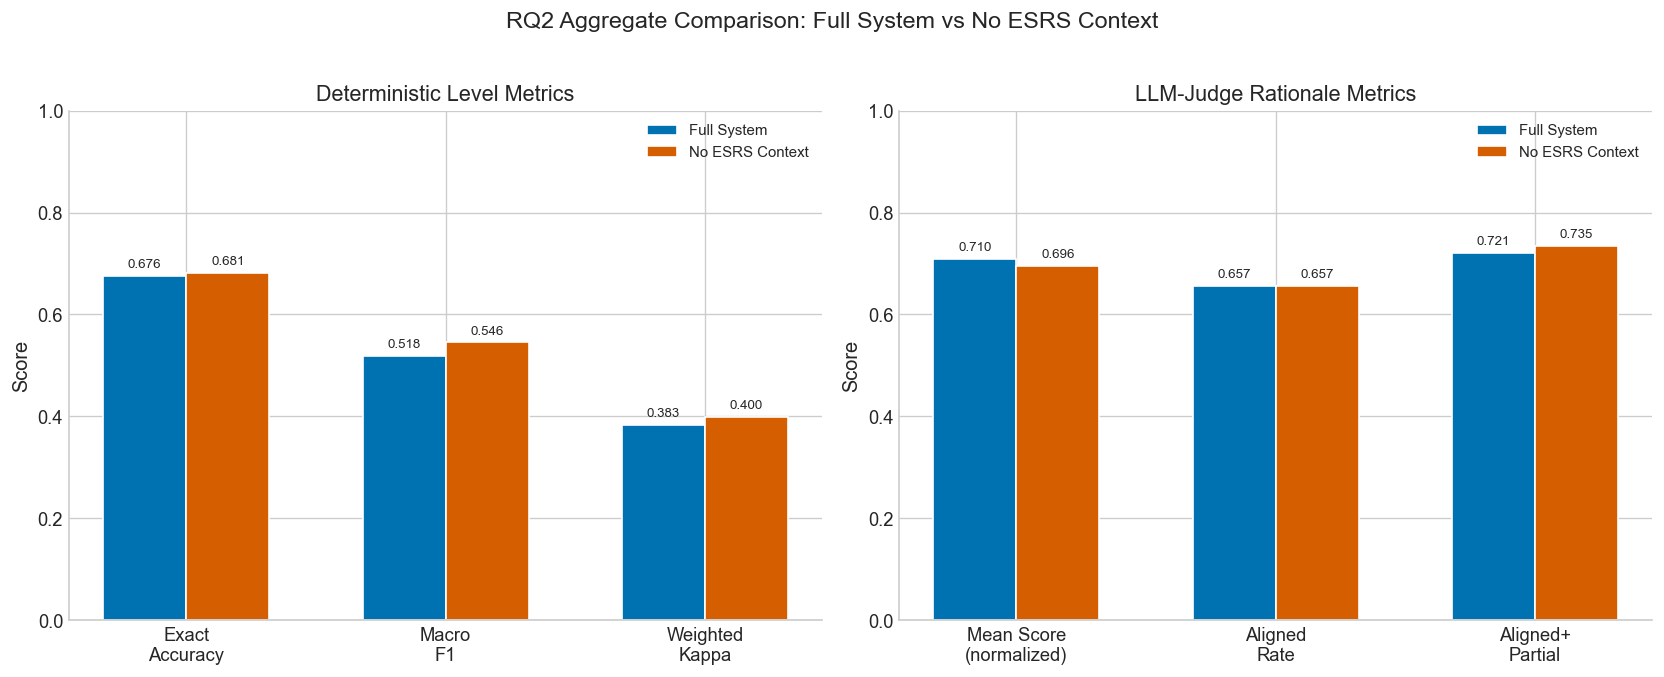

Saved: rq2_aggregate_comparison.png


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
w = 0.32

# Panel 1 — Deterministic level metrics
ax = axes[0]
det_metrics = ["exact_accuracy", "macro_f1", "weighted_kappa"]
det_labels = ["Exact\nAccuracy", "Macro\nF1", "Weighted\nKappa"]
x = np.arange(len(det_metrics))
vals_f = [lm["full_system"][m] for m in det_metrics]
vals_n = [lm["no_esrs_context"][m] for m in det_metrics]
bars1 = ax.bar(x - w/2, vals_f, w, label="Full System", color=CLR_FULL, edgecolor="white")
bars2 = ax.bar(x + w/2, vals_n, w, label="No ESRS Context", color=CLR_NO_ESRS, edgecolor="white")
ax.set_xticks(x); ax.set_xticklabels(det_labels)
ax.set_ylim(0, 1); ax.set_ylabel("Score")
ax.set_title("Deterministic Level Metrics")
ax.legend(fontsize=9)
for bar in list(bars1) + list(bars2):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f"{bar.get_height():.3f}", ha="center", va="bottom", fontsize=8)

# Panel 2 — LLM-judge rationale metrics
ax = axes[1]
jdg_metrics = ["mean_score_normalized", "aligned", "aligned_or_partial"]
jdg_labels = ["Mean Score\n(normalized)", "Aligned\nRate", "Aligned+\nPartial"]
x = np.arange(len(jdg_metrics))
vals_f = [jm["full_system"][m] for m in jdg_metrics]
vals_n = [jm["no_esrs_context"][m] for m in jdg_metrics]
bars1 = ax.bar(x - w/2, vals_f, w, label="Full System", color=CLR_FULL, edgecolor="white")
bars2 = ax.bar(x + w/2, vals_n, w, label="No ESRS Context", color=CLR_NO_ESRS, edgecolor="white")
ax.set_xticks(x); ax.set_xticklabels(jdg_labels)
ax.set_ylim(0, 1); ax.set_ylabel("Score")
ax.set_title("LLM-Judge Rationale Metrics")
ax.legend(fontsize=9)
for bar in list(bars1) + list(bars2):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f"{bar.get_height():.3f}", ha="center", va="bottom", fontsize=8)

fig.suptitle("RQ2 Aggregate Comparison: Full System vs No ESRS Context", fontsize=14, y=1.02)
plt.tight_layout()
fig.savefig(RQ2_RESULTS_DIR / "rq2_aggregate_comparison.png")
plt.show()
print("Saved: rq2_aggregate_comparison.png")

## 12. Confusion Matrices

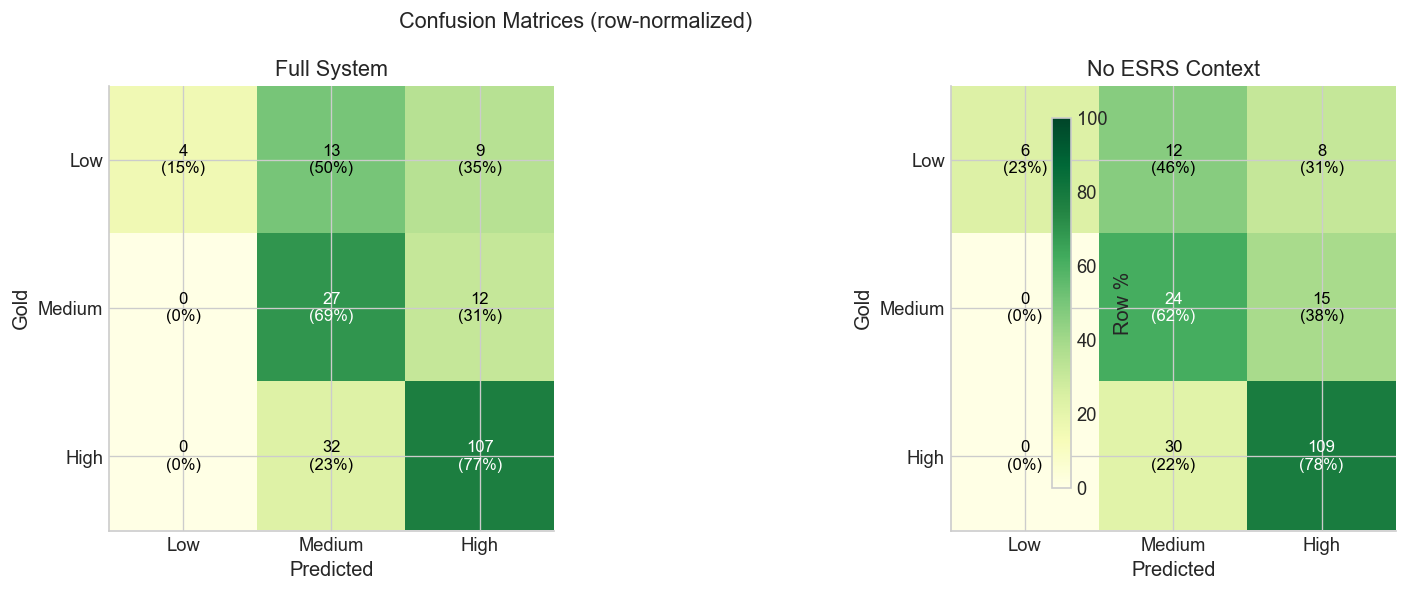

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (cond, title) in zip(axes, [("full_system", "Full System"),
                                      ("no_esrs_context", "No ESRS Context")]):
    cm = lm[cond]["confusion_matrix"]
    # Row-normalize for percentages
    row_sums = cm.sum(axis=1, keepdims=True)
    cm_pct = np.divide(cm, row_sums, where=row_sums > 0, out=np.zeros_like(cm, dtype=float)) * 100

    im = ax.imshow(cm_pct, cmap="YlGn", vmin=0, vmax=100)
    ax.set_xticks(range(3)); ax.set_yticks(range(3))
    ax.set_xticklabels(LABELS); ax.set_yticklabels(LABELS)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Gold")
    ax.set_title(title)

    for i in range(3):
        for j in range(3):
            txt = f"{cm[i, j]}\n({cm_pct[i, j]:.0f}%)"
            color = "white" if cm_pct[i, j] > 60 else "black"
            ax.text(j, i, txt, ha="center", va="center", fontsize=10, color=color)

fig.colorbar(im, ax=axes, shrink=0.8, label="Row %")
fig.suptitle("Confusion Matrices (row-normalized)", fontsize=13)
plt.tight_layout()
fig.savefig(RQ2_RESULTS_DIR / "rq2_confusion_matrices.png")
plt.show()

## 13. Per-ESRS-Standard Breakdown

Which of the 12 standards benefit most from ESRS context injection?

In [17]:
standards = sorted(set(s.esrs_standard for s in paired))
std_rows = []
for std in standards:
    ps_std = [s for s in paired if s.esrs_standard == std]
    jr_f = [judge_results["full_system"][i] for i, s in enumerate(paired) if s.esrs_standard == std]
    jr_n = [judge_results["no_esrs_context"][i] for i, s in enumerate(paired) if s.esrs_standard == std]
    lm_f = _level_metrics(ps_std, "full")
    lm_n = _level_metrics(ps_std, "no_esrs")
    jt_f = joint_metrics(ps_std, jr_f, "full_system")
    jt_n = joint_metrics(ps_std, jr_n, "no_esrs_context")
    std_rows.append({
        "Standard": std, "N": len(ps_std),
        "ExactAcc_Full": lm_f.get("exact_accuracy", float("nan")),
        "ExactAcc_NoESRS": lm_n.get("exact_accuracy", float("nan")),
        "MacroF1_Full": lm_f.get("macro_f1", float("nan")),
        "MacroF1_NoESRS": lm_n.get("macro_f1", float("nan")),
        "RatScore_Full": np.mean([r["rationale_score_normalized"] for r in jr_f]),
        "RatScore_NoESRS": np.mean([r["rationale_score_normalized"] for r in jr_n]),
        "AQS_Full": jt_f["aqs"], "AQS_NoESRS": jt_n["aqs"],
    })

std_df = pd.DataFrame(std_rows)
std_df["Delta_AQS"] = std_df["AQS_Full"] - std_df["AQS_NoESRS"]
std_df["Delta_ExactAcc"] = std_df["ExactAcc_Full"] - std_df["ExactAcc_NoESRS"]
std_df["Delta_MacroF1"] = std_df["MacroF1_Full"] - std_df["MacroF1_NoESRS"]

display_cols = ["Standard", "N", "ExactAcc_Full", "ExactAcc_NoESRS", "Delta_ExactAcc",
                "MacroF1_Full", "MacroF1_NoESRS", "Delta_MacroF1",
                "AQS_Full", "AQS_NoESRS", "Delta_AQS"]
print(std_df[display_cols].to_string(index=False, float_format="{:.3f}".format))

std_df.to_csv(RQ2_RESULTS_DIR / "rq2_per_standard_comparison.csv", index=False)
print("\nSaved: rq2_per_standard_comparison.csv")

Standard  N  ExactAcc_Full  ExactAcc_NoESRS  Delta_ExactAcc  MacroF1_Full  MacroF1_NoESRS  Delta_MacroF1  AQS_Full  AQS_NoESRS  Delta_AQS
  ESRS 2 34          0.559            0.559           0.000         0.349           0.349          0.000     0.522       0.478      0.044
 ESRS E1 17          0.647            0.647           0.000         0.383           0.383          0.000     0.647       0.632      0.015
 ESRS E2 17          0.706            0.706           0.000         0.443           0.468         -0.025     0.662       0.632      0.029
 ESRS E3 17          0.765            0.824          -0.059         0.474           0.722         -0.248     0.544       0.647     -0.103
 ESRS E4 17          0.765            0.588           0.176         0.478           0.353          0.125     0.765       0.515      0.250
 ESRS E5 17          0.824            0.824           0.000         0.586           0.556          0.031     0.779       0.765      0.015
 ESRS G1 17          0.765        

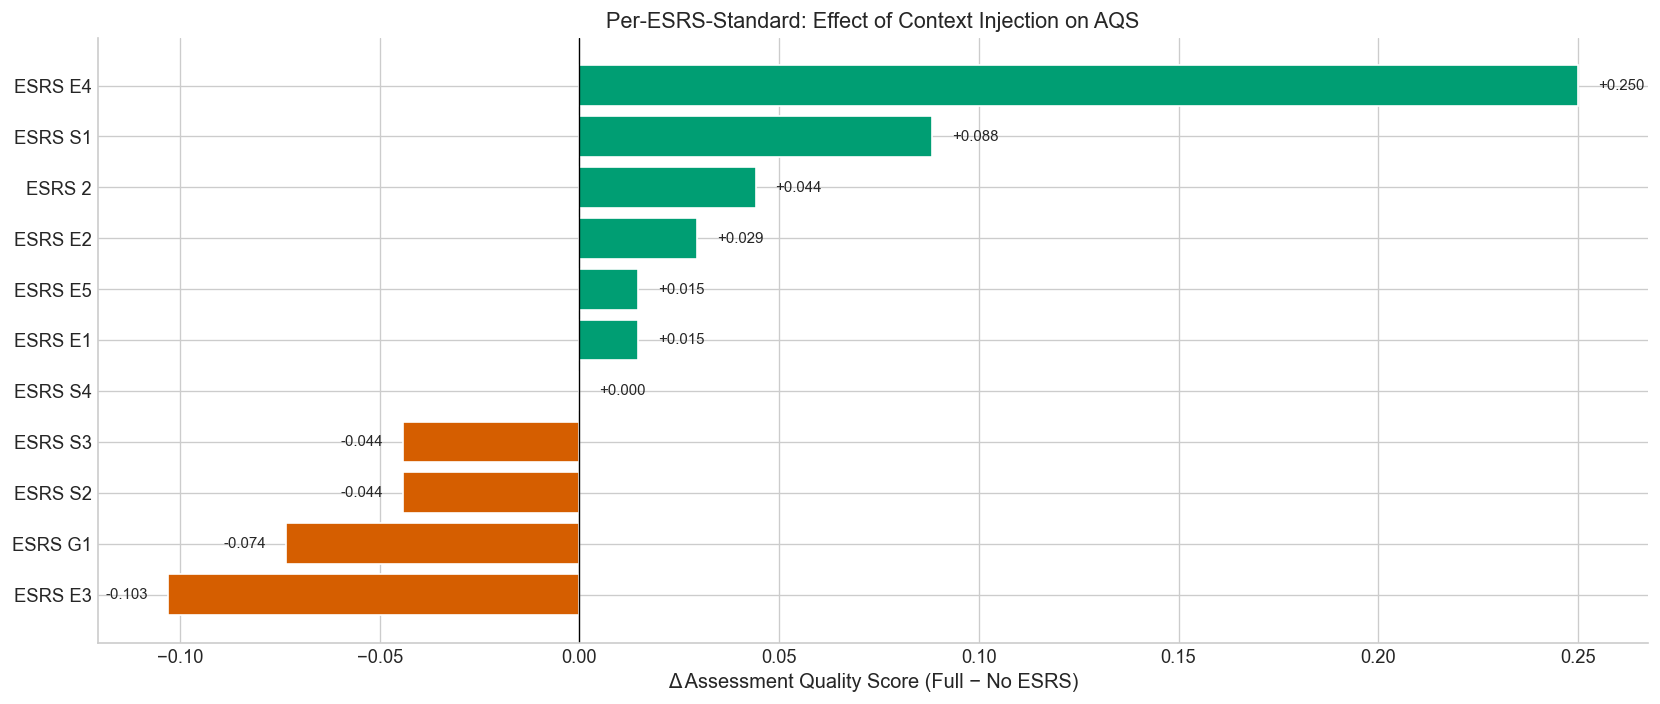

In [18]:
fig, ax = plt.subplots(figsize=(14, 6))
df_sorted = std_df.sort_values("Delta_AQS")
colors = [CLR_POS if d > 0 else CLR_NEG if d < 0 else CLR_ZERO
          for d in df_sorted["Delta_AQS"]]
bars = ax.barh(df_sorted["Standard"], df_sorted["Delta_AQS"], color=colors, edgecolor="white")
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Δ Assessment Quality Score (Full − No ESRS)")
ax.set_title("Per-ESRS-Standard: Effect of Context Injection on AQS")
for bar, val in zip(bars, df_sorted["Delta_AQS"]):
    x = bar.get_width()
    ax.text(x + 0.005 * (1 if x >= 0 else -1), bar.get_y() + bar.get_height()/2,
            f"{val:+.3f}", ha="left" if x >= 0 else "right", va="center", fontsize=9)
plt.tight_layout()
fig.savefig(RQ2_RESULTS_DIR / "rq2_per_standard.png")
plt.show()

## 14. Statistical Inference

### Wilcoxon Signed-Rank Test (Primary Confirmatory)

The Wilcoxon signed-rank test (Wilcoxon, 1945) is the primary confirmatory
test. It aggregates to the question level (n=12) to respect the nested
structure (17 companies per question), avoiding pseudo-replication. The
Wilcoxon test is preferred over the simpler sign test because it uses
**rank information** — the magnitude of differences, not just their
direction — giving higher power for small samples.

For n=12, exact p-values are computed by enumerating all 2¹² = 4,096
sign assignments of the rank statistic. The rank-biserial correlation *r*
serves as the non-parametric effect size (Kerby, 2014).

In [19]:
from rag.evaluation.rq2_metrics import (
    _wilcoxon_signed_rank_test, _cluster_bootstrap_ci, _cohens_d,
    _post_hoc_power,
)

# Aggregate to question level: AQS per question per condition
question_aqs = defaultdict(lambda: {"full": [], "no_esrs": []})
for i, s in enumerate(paired):
    pred_f = s.pred_level_full; pred_n = s.pred_level_no_esrs
    score_f = judge_results["full_system"][i]["rationale_score_normalized"]
    score_n = judge_results["no_esrs_context"][i]["rationale_score_normalized"]
    aqs_f = float(pred_f == s.gold_level) * score_f
    aqs_n = float(pred_n == s.gold_level) * score_n
    question_aqs[s.question_id]["full"].append(aqs_f)
    question_aqs[s.question_id]["no_esrs"].append(aqs_n)

q_deltas = {}
for qid in sorted(question_aqs):
    mean_f = np.mean(question_aqs[qid]["full"])
    mean_n = np.mean(question_aqs[qid]["no_esrs"])
    q_deltas[qid] = mean_f - mean_n

# Wilcoxon signed-rank test
wt = _wilcoxon_signed_rank_test(q_deltas)

# Cluster bootstrap CI
cb = _cluster_bootstrap_ci(q_deltas)

# Cohen's d
cd = _cohens_d(list(q_deltas.values()))

print("=" * 70)
print("PRIMARY TEST: Wilcoxon Signed-Rank (question-level AQS deltas)")
print("=" * 70)
print(f"  N questions      : {wt['n_questions']}")
print(f"  N effective      : {wt['n_effective']} (excl. ties)")
print(f"  Mean Δ           : {wt['mean_delta']:+.4f}")
print(f"  Median Δ         : {wt['median_delta']:+.4f}")
print(f"  W+               : {wt['w_plus']:.1f}")
print(f"  W−               : {wt['w_minus']:.1f}")
print(f"  W (test stat)    : {wt['w_statistic']:.1f}")
print(f"  p-value (exact)  : {wt['p_value']:.4f}")
print(f"  Rank-biserial r  : {wt['rank_biserial_r']:+.4f} ({wt['effect_magnitude']})")
print(f"  Cohen's d        : {cd['cohens_d']:+.4f} ({cd['effect_magnitude']})")
print(f"  95% Bootstrap CI : [{cb['ci_lower']:+.4f}, {cb['ci_upper']:+.4f}]")
sig = "Yes" if wt["p_value"] < 0.05 else "No"
print(f"  Significant (α=0.05): {sig}")
if cb["ci_lower"] <= 0 <= cb["ci_upper"]:
    print("  → CI includes zero: effect is NOT statistically defensible.")

# Post-hoc power (for transparency; should not be used for inference —
# Hoenig & Heisey, 2001, "The Abuse of Power")
power = _post_hoc_power(n=wt["n_effective"], effect_size=abs(cd["cohens_d"]))
print(f"\n  Post-hoc power   : {power['achieved_power']:.4f}  (MDES at 80%: {power['mdes_80pct']:.4f})")
if power["achieved_power"] < 0.80:
    print(f"  ⚠ Underpowered — cannot reliably detect effects of this magnitude.")

PRIMARY TEST: Wilcoxon Signed-Rank (question-level AQS deltas)
  N questions      : 12
  N effective      : 11 (excl. ties)
  Mean Δ           : +0.0184
  Median Δ         : +0.0074
  W+               : 37.0
  W−               : 29.0
  W (test stat)    : 29.0
  p-value (exact)  : 0.7480
  Rank-biserial r  : +0.1212 (small)
  Cohen's d        : +0.1945 (negligible)
  95% Bootstrap CI : [-0.0282, +0.0735]
  Significant (α=0.05): No
  → CI includes zero: effect is NOT statistically defensible.

  Post-hoc power   : 0.0540  (MDES at 80%: 1.6508)
  ⚠ Underpowered — cannot reliably detect effects of this magnitude.


## 15. Per-Sample Results Export

In [20]:
rows_out = []
for i, s in enumerate(paired):
    jf = judge_results["full_system"][i]
    jn = judge_results["no_esrs_context"][i]
    level_f = s.pred_level_full == s.gold_level
    level_n = s.pred_level_no_esrs == s.gold_level
    aqs_f = float(level_f) * jf["rationale_score_normalized"]
    aqs_n = float(level_n) * jn["rationale_score_normalized"]
    rows_out.append({
        "question_id": s.question_id, "company": s.company,
        "esrs_standard": s.esrs_standard, "gold_level": s.gold_level,
        "pred_full": s.pred_level_full, "pred_no_esrs": s.pred_level_no_esrs,
        "level_match_full": level_f, "level_match_no_esrs": level_n,
        "verdict_full": jf["rationale_verdict"],
        "score_full": jf["rationale_score"],
        "score_norm_full": jf["rationale_score_normalized"],
        "verdict_no_esrs": jn["rationale_verdict"],
        "score_no_esrs": jn["rationale_score"],
        "score_norm_no_esrs": jn["rationale_score_normalized"],
        "aqs_full": aqs_f, "aqs_no_esrs": aqs_n,
        "error_tags_full": ";".join(jf.get("error_tags", [])),
        "error_tags_no_esrs": ";".join(jn.get("error_tags", [])),
    })

df_out = pd.DataFrame(rows_out)
df_out.to_csv(RQ2_RESULTS_DIR / "rq2_per_sample_results.csv", index=False)
print(f"Saved {len(df_out)} rows to rq2_per_sample_results.csv")

# Show top 5 where ESRS context most improved AQS
df_out["delta_aqs"] = df_out["aqs_full"] - df_out["aqs_no_esrs"]
top5 = df_out.nlargest(5, "delta_aqs")[["question_id", "company", "gold_level",
                                         "pred_full", "pred_no_esrs", "delta_aqs"]]
print("\nTop 5 samples where ESRS context most improved AQS:")
print(top5.to_string(index=False))

Saved 204 rows to rq2_per_sample_results.csv

Top 5 samples where ESRS context most improved AQS:
question_id company gold_level pred_full pred_no_esrs  delta_aqs
         Q1    BASF       High      High       Medium        1.0
         Q1     Eni       High      High       Medium        1.0
         Q1  Repsol       High      High       Medium        1.0
         Q2 Aker BP       High      High       Medium        1.0
         Q2     OMV       High      High       Medium        1.0


## 16. Save Aggregate Results

In [21]:
summary = dict(
    rq2_version=RQ2_RESULTS_VERSION,
    judge_version=get_judge_version(),
    n_paired=len(paired),
    best_pipeline=_best_pipeline_name,
    gold_label_dist=dict(label_dist),
    majority_baseline=dict(label=maj, exact_accuracy=maj_acc, macro_f1=maj_f1),
    level_metrics={
        cond: {k: v for k, v in lm[cond].items()
               if k not in ("confusion_matrix", "per_label")}
        for cond in ["full_system", "no_esrs_context"]
    },
    judge_metrics={cond: {k: v for k, v in jm[cond].items() if k != "error_tags"}
                   for cond in CONDITIONS},
    joint_metrics={cond: jt[cond] for cond in CONDITIONS},
    primary_endpoint=dict(
        metric="assessment_quality_score",
        full_system=jt["full_system"]["aqs"],
        no_esrs_context=jt["no_esrs_context"]["aqs"],
        delta=jt["full_system"]["aqs"] - jt["no_esrs_context"]["aqs"],
    ),
    statistical=dict(
        primary_test=dict(
            test="wilcoxon_signed_rank",
            n=wt["n_questions"], n_eff=wt["n_effective"],
            p_value=wt["p_value"],
            w_plus=wt["w_plus"], w_minus=wt["w_minus"],
            rank_biserial_r=wt["rank_biserial_r"],
            effect_magnitude=wt["effect_magnitude"],
            cohens_d=cd["cohens_d"],
            bootstrap_ci=[cb["ci_lower"], cb["ci_upper"]],
            significant=wt["p_value"] < 0.05,
        ),
        power_analysis=dict(
            achieved_power=power["achieved_power"],
            mdes_80pct=power["mdes_80pct"],
            caveat="Post-hoc power should not be used for inference (Hoenig & Heisey, 2001).",
        ),
    ),
)

# Serialize (handle numpy types)


def _json_default(o):
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    raise TypeError(f"Not serializable: {type(o)}")


out_path = RQ2_RESULTS_DIR / "rq2_aggregate_results.json"
out_path.write_text(json.dumps(summary, indent=2, default=_json_default, ensure_ascii=False), "utf-8")
print(f"Saved: {out_path}")

Saved: /Users/sinahaghgoo/Library/CloudStorage/OneDrive-Persönlich/Master Thesis/Thesis Coding Part/ESRS-Regulation-Bot/data/artifacts/evaluation_results/rq2/rq2_aggregate_results.json


## 17. Interpretation

In [22]:
print("=" * 72)
print("RQ2 FINDINGS — Effect of Disclosure-Filtered ESRS Context Injection")
print("=" * 72)

# Primary endpoint
aqs_f = jt["full_system"]["aqs"]
aqs_n = jt["no_esrs_context"]["aqs"]
delta = aqs_f - aqs_n
print(f"\nPRIMARY ENDPOINT: Assessment Quality Score (AQS)")
print(f"  Full system    : {aqs_f:.4f}")
print(f"  No ESRS context: {aqs_n:.4f}")
print(f"  Δ              : {delta:+.4f}")
print(f"  Wilcoxon p     : {wt['p_value']:.4f}")
print(f"  95% CI         : [{cb['ci_lower']:+.4f}, {cb['ci_upper']:+.4f}]")

# Significance interpretation
if wt["p_value"] >= 0.05:
    print(f"\n→ The difference is NOT statistically significant (p = {wt['p_value']:.3f}).")
else:
    direction = "favours full system" if delta > 0 else "favours no-ESRS condition"
    print(f"\n→ The difference IS statistically significant (p = {wt['p_value']:.3f}, {direction}).")

# Power caveat
print(f"\nSTATISTICAL POWER:")
print(f"  Achieved power : {power['achieved_power']:.4f}")
print(f"  MDES at 80%    : {power['mdes_80pct']:.4f}")
if power["achieved_power"] < 0.80:
    print(f"  ⚠ The study is underpowered. With n=12 question clusters, the design")
    print(f"    can only detect very large effects (d > {power['mdes_80pct']:.2f}).")
    print(f"    The non-significant result does NOT confirm that ESRS context")
    print(f"    injection has no effect — it may simply be undetectable at this n.")

# Component breakdown
print(f"\nCOMPONENT BREAKDOWN:")
print(f"  {'Metric':<25s} {'Full':>8s} {'NoESRS':>8s} {'Δ':>8s}")
print(f"  {'─'*52}")
for m in ["exact_accuracy", "macro_f1", "weighted_kappa"]:
    vf = lm["full_system"].get(m, float("nan"))
    vn = lm["no_esrs_context"].get(m, float("nan"))
    print(f"  {m:<25s} {vf:>8.4f} {vn:>8.4f} {vf-vn:>+8.4f}")
for m in ["mean_score_normalized", "aligned", "misaligned"]:
    vf = jm["full_system"][m]
    vn = jm["no_esrs_context"][m]
    print(f"  {m:<25s} {vf:>8.4f} {vn:>8.4f} {vf-vn:>+8.4f}")
print(f"  {'AQS':<25s} {aqs_f:>8.4f} {aqs_n:>8.4f} {delta:>+8.4f}")

# Per-standard highlights
print(f"\nPER-STANDARD HIGHLIGHTS:")
for _, row in std_df.sort_values("Delta_AQS").iterrows():
    arrow = "↑" if row["Delta_AQS"] > 0.01 else "↓" if row["Delta_AQS"] < -0.01 else "→"
    print(f"  {arrow} {row['Standard']}: Δ AQS = {row['Delta_AQS']:+.3f} (n={int(row['N'])})")

# Conclusion
print(f"\nCONCLUSION:")
if wt["p_value"] >= 0.05 and power["achieved_power"] < 0.80:
    print(f"  The ESRS context injection effect is not statistically significant")
    print(f"  (p = {wt['p_value']:.3f}), but the study is underpowered to detect")
    print(f"  small-to-medium effects. The point estimates suggest a small")
    dirn = "advantage" if delta > 0 else "disadvantage"
    print(f"  {dirn} for ESRS context (Δ AQS = {delta:+.4f}), but this is")
    print(f"  well within the noise range (CI includes zero).")
    print(f"  The LLM's parametric knowledge of ESRS may be sufficient for")
    print(f"  this task, or a larger sample may be needed to isolate the effect.")

RQ2 FINDINGS — Effect of Disclosure-Filtered ESRS Context Injection

PRIMARY ENDPOINT: Assessment Quality Score (AQS)
  Full system    : 0.6336
  No ESRS context: 0.6152
  Δ              : +0.0184
  Wilcoxon p     : 0.7480
  95% CI         : [-0.0282, +0.0735]

→ The difference is NOT statistically significant (p = 0.748).

STATISTICAL POWER:
  Achieved power : 0.0540
  MDES at 80%    : 1.6508
  ⚠ The study is underpowered. With n=12 question clusters, the design
    can only detect very large effects (d > 1.65).
    The non-significant result does NOT confirm that ESRS context
    injection has no effect — it may simply be undetectable at this n.

COMPONENT BREAKDOWN:
  Metric                        Full   NoESRS        Δ
  ────────────────────────────────────────────────────
  exact_accuracy              0.6765   0.6814  -0.0049
  macro_f1                    0.5182   0.5455  -0.0273
  weighted_kappa              0.3830   0.3996  -0.0166
  mean_score_normalized       0.7096   0.6961  

In [23]:
print("Notebook complete!")

Notebook complete!
